In [143]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from oracle.custom_datasets.BTS import BTS_val_parquet_path, BTS_test_parquet_path, BTS_train_parquet_path

In [144]:
colors = {1: 'mediumaquamarine', 2: 'crimson', 3: 'goldenrod'}
filters = {1: 'g', 2: 'r', 3: 'i'}
markers = {1: 'o', 2: 's', 3: '^'}

In [145]:
val_df = pd.read_parquet(BTS_val_parquet_path)
test_df = pd.read_parquet(BTS_test_parquet_path)
df = pd.concat([val_df, test_df], ignore_index=True)

In [146]:
def plot_ztf_sample(id, pred,  save=False):

    gs_kw = dict(width_ratios=[3, 1], height_ratios=[2, 1])
    fig, axd = plt.subplot_mosaic([['left', 'upper right'],
                                ['left', 'lower right']],
                                    gridspec_kw=gs_kw,
                                figsize=(9.5, 4), layout="constrained")
    for k in ['upper right', 'lower right']:
        axd[k].set_xticks([])
        axd[k].set_yticks([])

    sample = df[df['ZTFID'] == id]
    label = sample['bts_class'].to_numpy()[0]

    t = sample['jd'].to_numpy()[0]
    t = t - np.min(t)

    mag = sample['magpsf'].to_numpy()[0]
    mag_err = sample['sigmapsf'].to_numpy()[0]
    band = sample['fid'].to_numpy()[0]

    ra = sample['ra'].to_numpy()[0][0]
    dec = sample['dec'].to_numpy()[0][0]
    drb = sample['drb'].to_numpy()[0][0]
    sgscore = sample['sgscore1'].to_numpy()[0][0]
    scorr = sample['scorr'].to_numpy()[0][0]


    for b in np.unique(band):
        mask = band == b
        axd['left'].errorbar(t[mask], mag[mask], yerr=mag_err[mask], fmt=markers[b], label=filters[b], color=colors[b], mec='white', markersize=10)

    axd['left'].text(0.05, 0.1, f"{id} (True: {label} | Pred: {pred})", transform=axd['left'].transAxes, fontsize='xx-large', verticalalignment='top')
    axd['left'].set_ylim(top=20.8)

    axd['left'].invert_yaxis()
    axd['left'].set_xlabel('Days since first detection', fontsize='xx-large')
    axd['left'].set_ylabel('mag', fontsize='xx-large')

    ps_data = sample['ps'].iloc[0]

    img = np.asarray(ps_data).reshape((3, 252, 252))
    img = np.permute_dims(img, (1,2,0))  # swap x and y for correct orientation

    axd['upper right'].imshow(img)


    text = f"RA: {ra:.3f}\nDec: {dec:.3f}\nSG Score: {sgscore:.2f}\nScorr: {scorr:.2f}"

    axd['lower right'].text(0, 0, text, transform=axd['lower right'].transAxes,
                        fontsize='xx-large', color='black', ha='left', va='bottom')   
    axd['lower right'].axis('off') 


    # make legend a separate figure
    # fig_legend = plt.figure(figsize=(3, 1))
    # ax_legend = fig_legend.add_subplot()
    # for b in np.unique(band):
    #     mask = band == b
    #     ax_legend.plot([], [], markers[b], label=filters[b], color=colors[b])
    # # make it 3 column
    # ax_legend.legend(ncol=3)
    # ax_legend.axis('off')


    if save:
        fig.savefig(f"{label}_{id}.pdf")
        #fig_legend.savefig(f"legend.pdf")
    else:
        plt.show()

In [ ]:
base = "../../models"
pro_model_path = f"{base}/BTSv2-pro/summer-feather-611"
base_model_path = f"{base}/BTSv2/peachy-sweep-4"

paths = {
    'Oracle-2': base_model_path,
    'Oracle-2 Omni': pro_model_path,
}


In [184]:
def get_day_preds(model, day):

    embedding_file_path = paths[model]+f'/embeddings/embeddings+{day}.csv'
    df = pd.read_csv(embedding_file_path)
    return df


In [185]:
def get_incorrect_preds(model, day):
    df = get_day_preds(model, day)
    
    # Only return rows where the model makes a mistake
    return df.loc[((df['pred']!=df['class']) & (df['class']=='Anomaly'))]


In [186]:
d = 128
df_failed_omni = get_incorrect_preds('Oracle-2 Omni', d)

In [213]:
# make asymmetric confusion matrix

def make_assymetric_confusion_matrix(pred, true):

    true_classes_unique = np.unique(true)
    pred_classes_unique = np.unique(pred)

    true_classes = np.array(['LINER', 'TDE', 'star', 'LBV', 'Ca-rich', 'ILRT', 'FBOT', "Ien", 'LRN','microlensing', 'rock', 'bogus?' ])
    pred_classes = np.array(['AGN','CV', 'Varstar','SN-Ia', 'SN-II', 'SN-Ib/c', 'SLSN'])

    assert set(true_classes) == set(true_classes_unique), f"True classes must be a subset of the unique true classes {set(true_classes_unique)-set(true_classes)}"
    assert set(pred_classes) == set(pred_classes_unique), f"Predicted classes must be a subset of the unique predicted classes {set(pred_classes_unique)-set(pred_classes)}"

    confusion_matrix = np.zeros((len(true_classes), len(pred_classes)), dtype=int)
    for t, p in zip(true, pred):
        true_idx = np.where(true_classes == t)[0][0]
        pred_idx = np.where(pred_classes == p)[0][0]
        confusion_matrix[true_idx, pred_idx] += 1
    return confusion_matrix, true_classes, pred_classes

def plot_assymetric_confusion_matrix(pred, true, title, normalize=True):

    og_confusion_matrix, true_classes, pred_classes = make_assymetric_confusion_matrix(pred, true)

    if normalize:
    # Normalize the confusion matrix by row (true class)
        row_sums = og_confusion_matrix.sum(axis=1, keepdims=True)
        confusion_matrix = og_confusion_matrix / row_sums
    else:
        confusion_matrix = og_confusion_matrix   

    c_list = ["#FFFFFF", "#FF6645"] 
    my_cmap = LinearSegmentedColormap.from_list("custom_blue", c_list, N=256)

    fig, ax = plt.subplots(figsize=(6, 9))
    im = ax.imshow(confusion_matrix, cmap=my_cmap)

    # Show all ticks and label them with the respective list entries
    ax.set_xticks(np.arange(len(pred_classes)))
    ax.set_yticks(np.arange(len(true_classes)))

    ax.set_xticklabels(pred_classes)
    ax.set_yticklabels(true_classes)

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
             rotation_mode="anchor")
    
    plt.setp(ax.get_yticklabels(), rotation=45, va="center",
             rotation_mode="anchor")

    # Loop over data dimensions and create text annotations.
    for i in range(len(true_classes)):
        for j in range(len(pred_classes)):
            if confusion_matrix[i, j] > 0.5:
                color = "white"
            else:                
                color = "black"
            text = ax.text(j, i, f"{confusion_matrix[i, j]:.2f}\n({og_confusion_matrix[i, j]})",
                           ha="center", va="center", color=color)

    # make a 3x3 box around the top left 3x3 corner of the confusion matrix
    # ax.plot([-0.5, 2.5, 2.5, -0.5, -0.5], [-0.5, -0.5, 2.5, 2.5, -0.5], color='black', linewidth=2)

    # # make a 6x4 box starting from the bottom right corner of the 3x3 box
    # ax.plot([2.5, 8.5, 8.5, 2.5, 2.5], [2.5, 2.5, 9.5, 9.5, 2.5], color='black', linewidth=2)
            
    plt.xlabel('Predicted Class', fontsize='x-large', fontweight='bold')
    plt.ylabel('True Class', fontsize='x-large', fontweight='bold')

    ax.set_title(title, fontsize='x-large', fontweight='bold')
    fig.tight_layout()
    plt.savefig(f"failure_modes_omni.pdf")
    plt.show()

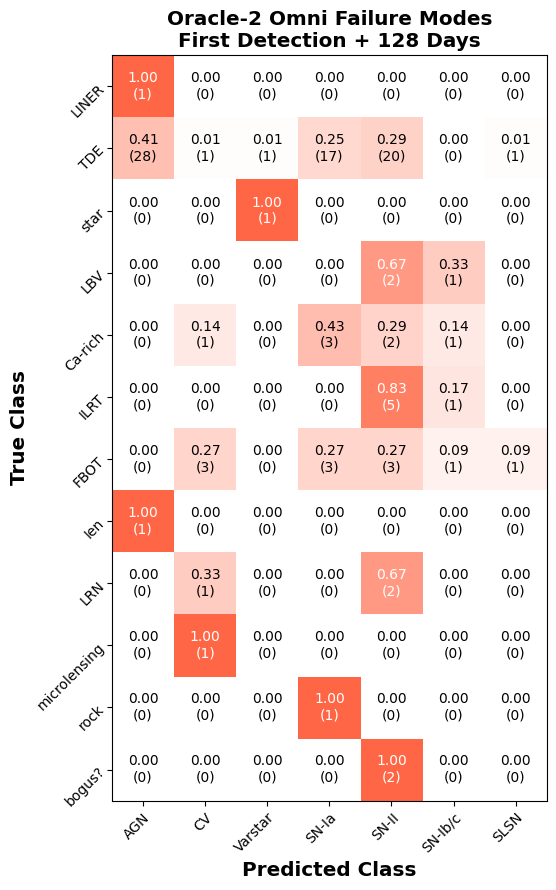

In [214]:
plot_assymetric_confusion_matrix(df_failed_omni['pred'], df_failed_omni['raw_class'], f'Oracle-2 Omni Failure Modes\nFirst Detection + {d} Days')

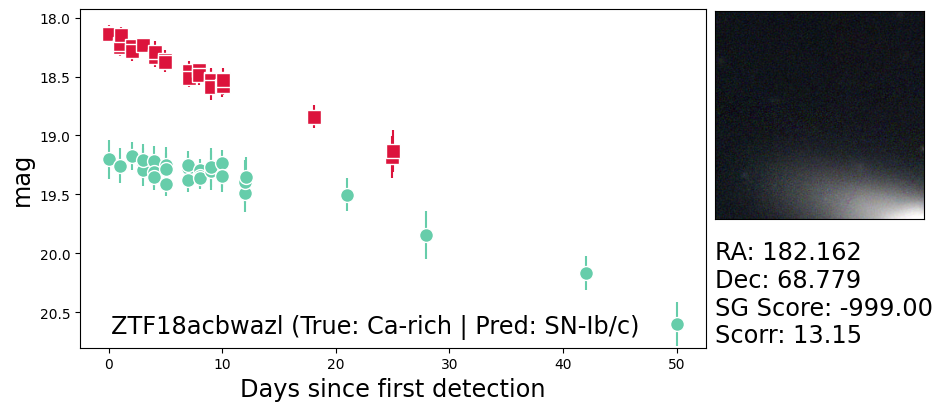

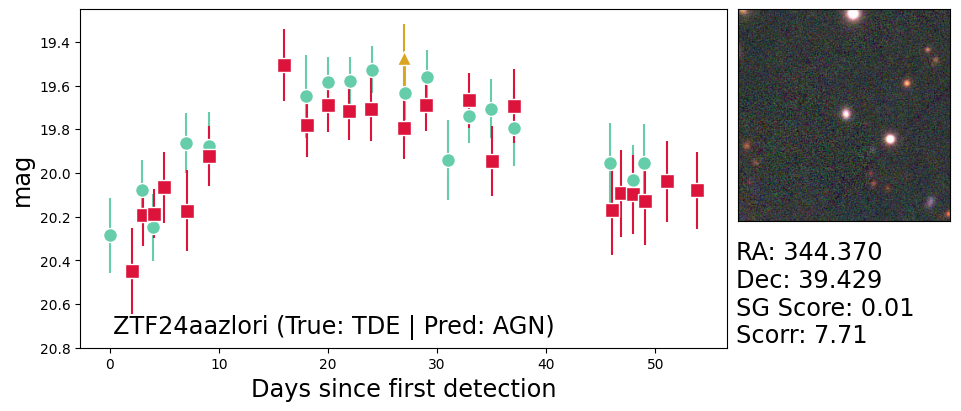

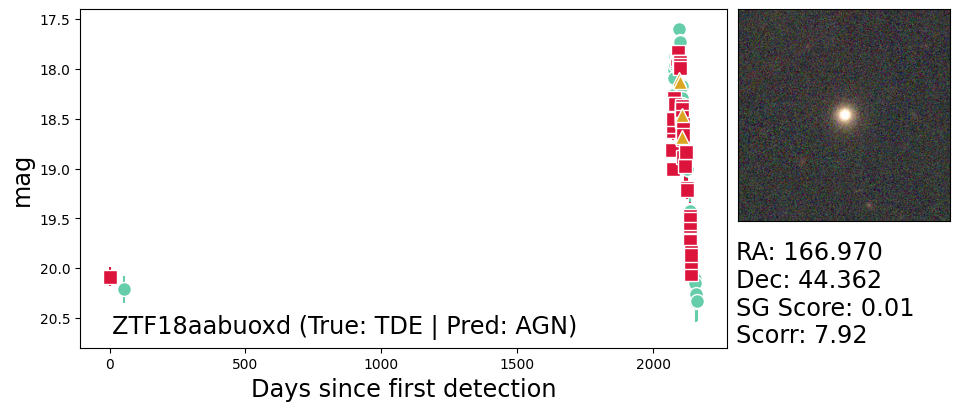

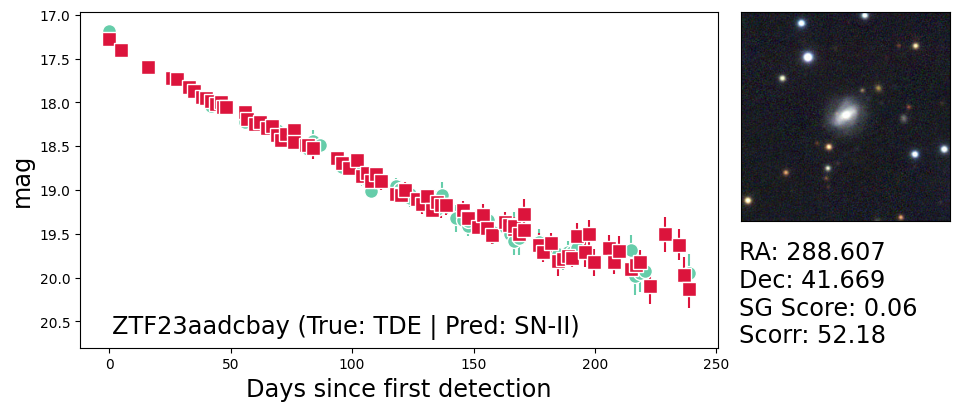

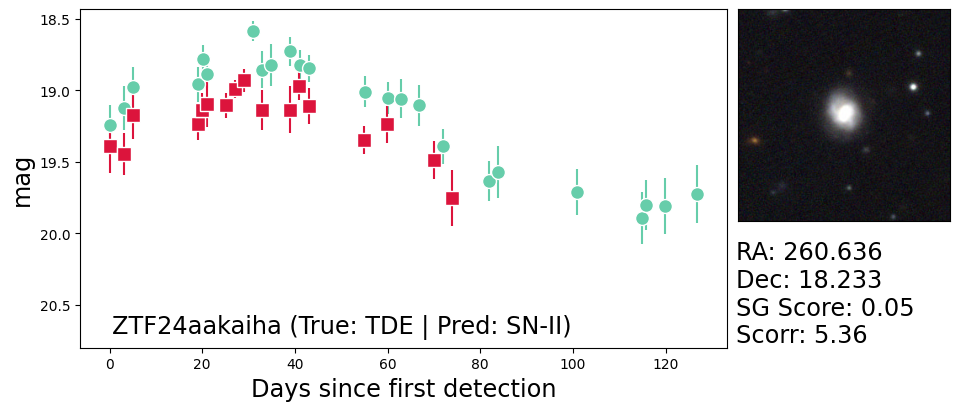

...

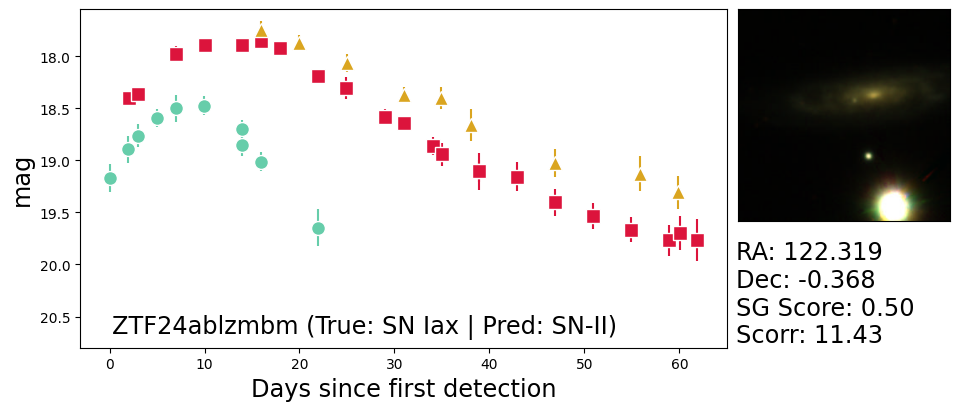

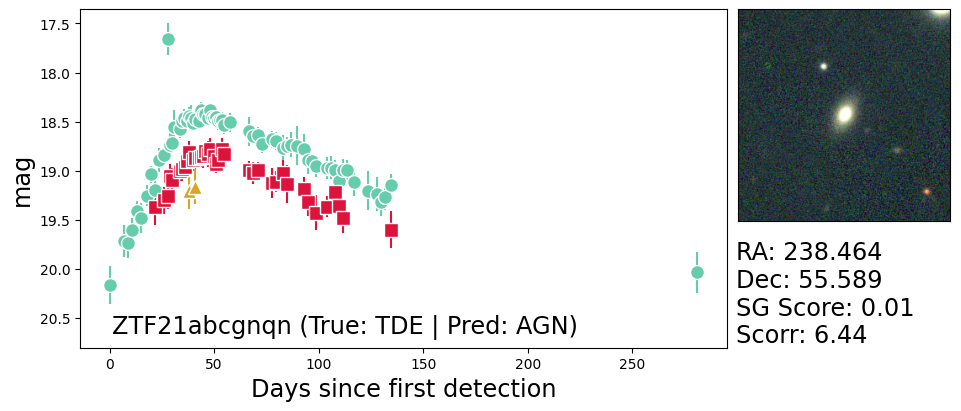

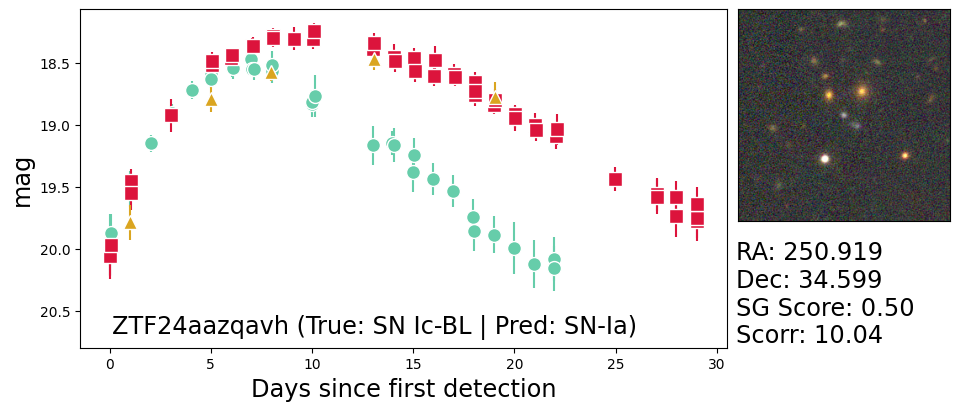

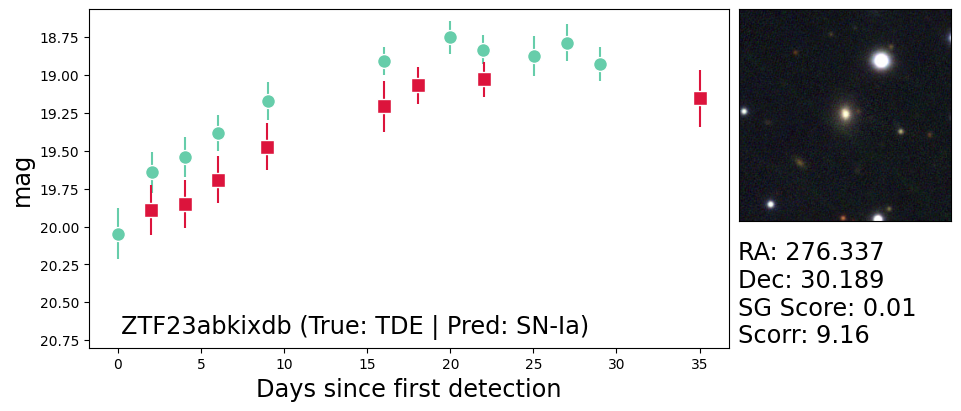

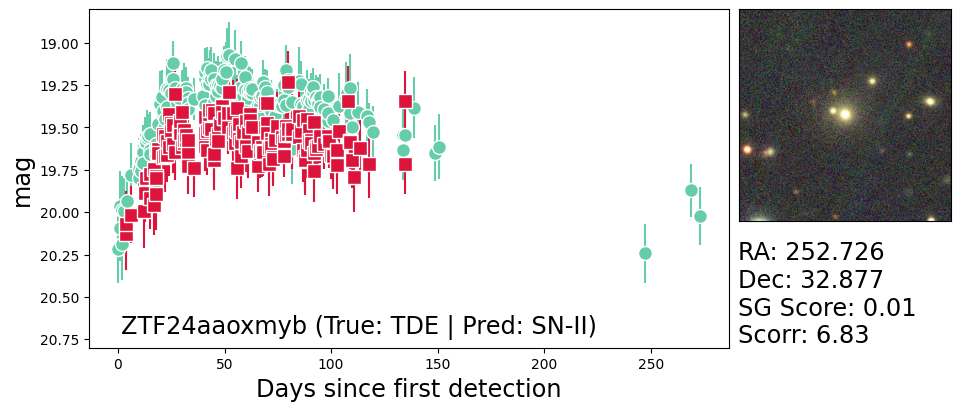

In [160]:
for row in df_failed_omni.iterrows():
    pred = row[1]['pred']
    ZTFID = row[1]['id']
    plot_ztf_sample(ZTFID, pred)
